# 03b · Chart Images: Extraction + Cross-check
**Grounded Conversational Chart Accessibility** — Section 3b (extension)

**The question this notebook answers:** *if a user only has a chart **image** (no data file), can the verification layer still stop hallucinated answers?*

Sections 1–3 used ChartQA's true data tables. Here the table must first be **read from the picture**, and that reading can itself be wrong. So:

1. **Two different vision models** (`qwen2.5vl:3b`, `gemma3:4b`) each read every chart into a table.
2. **Cross-check:** values both models agree on (within 5%) are **confirmed**; the rest are **uncertain**.
3. Your **oracle** computes the answer from the confirmed table, and your **verifier** checks the vision model's own answer against it.
4. Every final answer gets an honest label:
   - **verified**: every value it depends on was confirmed by both models,
   - **estimated**: it depends on at least one uncertain value,
   - **unverified**: the oracle couldn't handle the question on the extracted table.

Because ChartQA gives us **both the image and the true table**, we can measure what matters: how often each model misreads, whether the cross-check catches misreads, and how accurate "verified" answers really are.

**Before running:** the Ollama app must be running, and both models downloaded:
```
ollama pull qwen2.5vl:3b
ollama pull gemma3:4b
```
**Time:** each chart costs 3 vision calls (2 readings + 1 answer). On a CPU that's roughly 1–3 minutes per chart, so 40 charts takes 1–2 hours. Everything is cached: if it stops, rerun and it continues.

## 3b.1 Setup

In [ ]:
import sys, logging
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src import config
from src.data_utils import load_table, download_images
from src.oracle import oracle
import src.verify as V
from src.verify import verify_one, template_answer, fmt_value
from src.llm import ask, ResponseCache, ollama_ready
from src.extract import (extract_table, score_extraction, cross_check, confirmed_correct,
                         answer_confidence, same_labels, oracle_on_reading, image_b64,
                         answer_prompt, ANSWER_SYSTEM)

config.make_dirs()
config.set_seeds()
logging.basicConfig(filename=config.LOG_DIR / "03b_images.log", filemode="a",
                    level=logging.INFO, format="%(levelname)s | %(message)s", force=True)
pd.set_option("display.max_colwidth", 80)
cache = ResponseCache()
print("Vision models:", [m["model"] for m in config.VISION_MODELS])

Vision models: ['qwen2.5vl:3b', 'gemma3:4b']


## 3b.2 Choose the charts and download their images

We reuse your **validated** 200-question sample from Section 1 (every question there has an oracle answer that matches ChartQA's human answer). We take **one question per chart** and spread the charts across question types, then download only those images.

In [ ]:
sample = pd.read_csv(config.OUTPUT_DIR / "eval_sample.csv")
one_per_chart = sample.drop_duplicates("table_file")

per_type = int(np.ceil(config.N_IMAGE_CHARTS / one_per_chart["qtype"].nunique()))
picked = pd.concat([g.sample(min(len(g), per_type), random_state=config.SEED)
                    for _, g in one_per_chart.groupby("qtype")])
if len(picked) < config.N_IMAGE_CHARTS:                     # top up with leftovers
    rest = one_per_chart.drop(picked.index)
    picked = pd.concat([picked, rest.sample(min(config.N_IMAGE_CHARTS - len(picked), len(rest)),
                                            random_state=config.SEED)])
charts = picked.head(config.N_IMAGE_CHARTS).reset_index(drop=True)
charts["imgname"] = charts["table_file"].str.replace(".csv", ".png", regex=False)

download_images(charts["imgname"].tolist())
TRUE = {f: load_table(f) for f in charts["table_file"]}
print(f"{len(charts)} charts selected")
display(pd.crosstab(charts["qtype"], charts["chart_type"], margins=True))

40 charts selected


chart_type,bar,line,pie,All
qtype,,,,
avg,3,0,2,5
compare,1,0,4,5
diff,2,2,1,5
lookup,2,3,0,5
max,4,1,0,5
min,2,2,1,5
sum,0,2,3,5
trend,0,5,0,5
All,14,15,11,40


What is the average of global mismanaged plastic South Asia and Latin America and Caribbean?


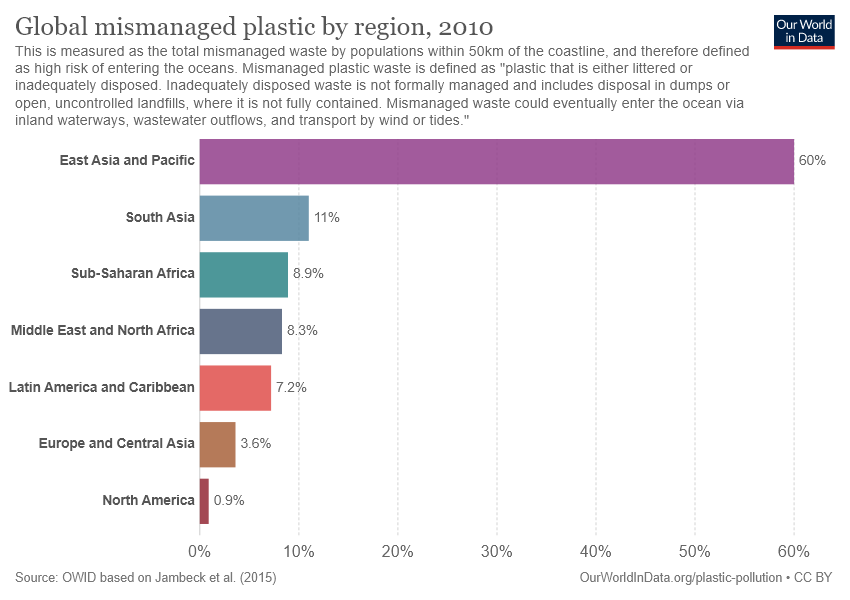

,"Global mismanaged plastic by region, 2010"
Country,
East Asia and Pacific,60.0
South Asia,11.0
Sub-Saharan Africa,8.9
Middle East and North Africa,8.3
Latin America and Caribbean,7.2
Europe and Central Asia,3.6
North America,0.9


In [ ]:
# What a vision model sees (change 0 to look at others)
ex = charts.iloc[0]
print(ex["query"])
display(Image(filename=str(config.TEST_DIR / "png" / ex["imgname"]), width=500))
TRUE[ex["table_file"]]

## 3b.3 Check the vision models are ready

In [ ]:
ready = [m for m in config.VISION_MODELS if ollama_ready(m["model"])]
print("Ready:", [m["name"] for m in ready])
assert len(ready) == 2, "Both vision models are needed for the cross-check (see the message above)."

Ready: ['qwen2.5vl-3b', 'gemma3-4b']


## 3b.4 Read every chart with both models

This is the slow step. Leave `RUN_LIMIT = 3` for a first test (about 10 minutes), check the readings in 3b.5 look sensible, then set `RUN_LIMIT = None` and rerun for all charts. Finished readings load instantly from the cache.

In [ ]:
RUN_LIMIT = None       # None = all charts (cached, so instant now); 3 = quick test

todo = charts if RUN_LIMIT is None else charts.head(RUN_LIMIT)
READINGS = {}          # (imgname, model name) -> {"raw", "table", "error", ...}
for i, r in enumerate(todo.itertuples(), 1):
    for m in config.VISION_MODELS:
        READINGS[(r.imgname, m["name"])] = rec = extract_table(m, r.imgname, cache)
        how = "cached" if rec["cached"] else f"{rec['latency_s']:.0f}s"
        status = "ok" if rec["table"] is not None else ("ERROR" if rec["error"] else "unparsed")
        print(f"  [{i}/{len(todo)}] {r.imgname:28s} {m['name']:13s} {status:8s} {how}")
charts_done = todo.copy()

  [1/40] 94483094006737.png           qwen2.5vl-3b  ok       cached
  [1/40] 94483094006737.png           gemma3-4b     ok       cached
  [2/40] two_col_24548.png            qwen2.5vl-3b  ok       cached
  [2/40] two_col_24548.png            gemma3-4b     ok       cached
  [3/40] OECD_INFANT_MORTALITY_RATES_EST_NZL_000048.png qwen2.5vl-3b  ok       cached
  [3/40] OECD_INFANT_MORTALITY_RATES_EST_NZL_000048.png gemma3-4b     ok       cached
  [4/40] two_col_24593.png            qwen2.5vl-3b  ok       cached
  [4/40] two_col_24593.png            gemma3-4b     ok       cached
  [5/40] 39067786005185.png           qwen2.5vl-3b  ok       cached
  [5/40] 39067786005185.png           gemma3-4b     ok       cached
  [6/40] multi_col_80102.png          qwen2.5vl-3b  ok       cached
  [6/40] multi_col_80102.png          gemma3-4b     ok       cached
  [7/40] two_col_41953.png            qwen2.5vl-3b  ok       cached
  [7/40] two_col_41953.png            gemma3-4b     ok       cached
  [8/40] two

In [ ]:
# Compare one reading with the truth (change the index to inspect others)
ex = charts_done.iloc[0]
for m in config.VISION_MODELS:
    print(f"--- {m['name']} read:")
    display(READINGS[(ex["imgname"], m["name"])]["table"])
print("--- TRUE table:")
TRUE[ex["table_file"]]

--- qwen2.5vl-3b read:


,value
label,
East Asia and Pacific,60.0
South Asia,11.0
Sub-Saharan Africa,8.9
Middle East and North Africa,8.3
Latin America and Caribbean,7.2
Europe and Central Asia,3.6
North America,0.9


--- gemma3-4b read:


,value
label,
East Asia and Pacific,60.0
South Asia,11.0
Sub-Saharan Africa,8.9
Middle East and North Africa,8.3
Latin America and Caribbean,7.2
Europe and Central Asia,3.6
North America,0.9


--- TRUE table:


,"Global mismanaged plastic by region, 2010"
Country,
East Asia and Pacific,60.0
South Asia,11.0
Sub-Saharan Africa,8.9
Middle East and North Africa,8.3
Latin America and Caribbean,7.2
Europe and Central Asia,3.6
North America,0.9


## 3b.5 How accurately does each model read charts?

Each reading is compared **cell by cell** with ChartQA's true table. A value counts as read correctly if it is within 5% of the truth.

- `parsed_%`: replies we could turn into a table at all,
- `label_recall_%`: categories/years found,
- `cell_accuracy_%`: true values read correctly (out of all true values).

In [ ]:
rows = []
for r in charts_done.itertuples():
    for m in config.VISION_MODELS:
        s = score_extraction(READINGS[(r.imgname, m["name"])]["table"], TRUE[r.table_file])
        rows.append({"model": m["name"], "chart_type": r.chart_type, **s})
ext = pd.DataFrame(rows)

def extraction_summary(g):
    return pd.Series({
        "charts": len(g),
        "parsed_%": round(100 * g["parsed"].mean(), 1),
        "label_recall_%": round(100 * g["label_recall"].mean(), 1),
        "cell_accuracy_%": round(100 * g["cells_correct"].sum() / g["true_cells"].sum(), 1),
    })

ext_summary = ext.groupby("model").apply(extraction_summary)
ext_summary.to_csv(config.TABLE_OUT / "image_extraction.csv")
display(ext_summary)
ext.groupby(["model", "chart_type"]).apply(extraction_summary)

,charts,parsed_%,label_recall_%,cell_accuracy_%
model,,,,
gemma3-4b,40.0,97.5,95.9,65.3
qwen2.5vl-3b,40.0,100.0,98.4,96.6


charts  parsed_%  label_recall_%  cell_accuracy_%
model        chart_type                                                   
gemma3-4b    bar           14.0      92.9            91.9             81.5
             line          15.0     100.0            97.9             57.4
             pie           11.0     100.0            98.2             62.5
qwen2.5vl-3b bar           14.0     100.0            99.0             97.0
             line          15.0     100.0            99.5             97.3
             pie           11.0     100.0            95.9             91.7

## 3b.6 Does the cross-check catch misreads?

For each chart we compare the two readings. Then, using the true table, we check:
- **confirmed values**: how many are actually right? (should be very high)
- **uncertain values**: how many are actually right? (lower, otherwise the cross-check isn't telling us anything)

The most important number is **`both_agree_but_wrong`**: values both models misread the *same* way. The cross-check cannot catch these; it is the residual risk of the whole image pipeline.

In [ ]:
CONS, UNC, BOTH, SAME = {}, {}, {}, {}
cc_rows = []
for r in charts_done.itertuples():
    t1 = READINGS[(r.imgname, config.VISION_MODELS[0]["name"])]["table"]
    t2 = READINGS[(r.imgname, config.VISION_MODELS[1]["name"])]["table"]
    BOTH[r.imgname] = [t for t in (t1, t2) if t is not None]
    SAME[r.imgname] = same_labels(t1, t2)                    # did both find the same categories?
    CONS[r.imgname], UNC[r.imgname] = cross_check(t1, t2)
    cc_rows.append(confirmed_correct(CONS[r.imgname], UNC[r.imgname], TRUE[r.table_file]))
cc = pd.DataFrame(cc_rows).sum()

cross_check_summary = pd.Series({
    "confirmed_values": cc["confirmed"],
    "confirmed_right_%": round(100 * cc["confirmed_right"] / max(cc["confirmed"], 1), 1),
    "uncertain_values": cc["uncertain"],
    "uncertain_right_%": round(100 * cc["uncertain_right"] / max(cc["uncertain"], 1), 1),
    "both_agree_but_wrong": cc["confirmed"] - cc["confirmed_right"],
})
cross_check_summary.to_csv(config.TABLE_OUT / "image_crosscheck.csv")
cross_check_summary

confirmed_values        285.0
confirmed_right_%        99.3
uncertain_values        151.0
uncertain_right_%        94.7
both_agree_but_wrong      2.0
dtype: float64

## 3b.7 "Before": the vision model answers straight from the image

This is what a user gets today from a plain vision LLM: upload a chart, ask a question, get an answer, with no checking. We grade each answer against the **true** answer (from Section 1), with the same verifier rules as Section 3.

In [ ]:
answerer = config.VISION_MODELS[0]
results = []
for i, r in enumerate(charts_done.itertuples(), 1):
    rec = ask(answerer, answer_prompt(r.query), cache, system=ANSWER_SYSTEM,
              images=[image_b64(r.imgname)])
    graded = verify_one(rec["answer"], r.oracle_answer, r.answer_kind, r.query, r.qtype,
                        "short", TRUE[r.table_file])
    results.append({"qid": r.qid, "imgname": r.imgname, "qtype": r.qtype,
                    "chart_type": r.chart_type, "query": r.query, "true_answer": r.label,
                    "llm_answer": rec["answer"], "llm_correct": graded["status"] == "correct"})
    print(f"  {i}/{len(charts_done)} answered")
res = pd.DataFrame(results)
print(f"\nVision model alone, wrong answers: {100 * (1 - res['llm_correct'].mean()):.1f}%")

  1/40 answered
  2/40 answered
  3/40 answered
  4/40 answered
  5/40 answered
  6/40 answered
  7/40 answered
  8/40 answered
  9/40 answered
  10/40 answered
  11/40 answered
  12/40 answered
  13/40 answered
  14/40 answered
  15/40 answered
  16/40 answered
  17/40 answered
  18/40 answered
  19/40 answered
  20/40 answered
  21/40 answered
  22/40 answered
  23/40 answered
  24/40 answered
  25/40 answered
  26/40 answered
  27/40 answered
  28/40 answered
  29/40 answered
  30/40 answered
  31/40 answered
  32/40 answered
  33/40 answered
  34/40 answered
  35/40 answered
  36/40 answered
  37/40 answered
  38/40 answered
  39/40 answered
  40/40 answered

Vision model alone, wrong answers: 12.5%


## 3b.8 "After": the full layer on images

For each question:
1. the **oracle** computes the answer from the cross-checked (consensus) table,
2. the **verifier** checks the vision model's answer against it,
3. **final answer** = the model's answer if it passes, otherwise a template built from the oracle,
4. **label** = *verified* / *estimated* / *unverified* (see the top of the notebook).

Two safeguards:
- **Don't override a plausible answer with a shaky reading.** Where the readings disagree, we don't know which is right. So the model's answer is kept if it matches the answer computed from **either** reading; it is only replaced when it matches neither.
- **Missing categories.** A "highest/lowest/trend" answer is only *verified* if both readings found the same categories, since a dropped bar could change the answer.

Then every final answer is graded against the **true** answer.

In [ ]:
def matches(answer, table, r):
    "Does the model's answer match the oracle computed from this reading?"
    res, _, used, _ = oracle_on_reading(r.query, r.qtype, table)
    if res is None:
        return False
    return verify_one(answer, res["answer"], res["answer_kind"], r.query, r.qtype,
                      "short", used)["status"] == "correct"

def run_layer(r):
    cons, unc = CONS[r.imgname], UNC[r.imgname]
    if cons is None:                                     # neither model could read the chart
        return r.llm_answer, "unverified", "short", "no_reading"
    # the oracle tries the reading both ways round (multi-series charts can be written sideways)
    result, reason, cons, unc = oracle_on_reading(r.query, r.qtype, cons, unc)
    if result is None:                                   # can't compute from the reading
        return r.llm_answer, "unverified", "short", reason
    label = answer_confidence(r.query, r.qtype, cons, unc, SAME[r.imgname])
    if any(matches(r.llm_answer, t, r) for t in [cons] + BOTH[r.imgname]):
        return r.llm_answer, label, "short", "llm_matched_oracle"
    text = template_answer(result["answer"], result["answer_kind"])
    if label == "estimated":
        text = text.replace("The answer is", "The answer is approximately") + " (estimated from the chart)"
    return text, label, "sentence", "replaced_by_oracle"

out = res.merge(charts_done[["qid", "oracle_answer", "answer_kind", "table_file"]], on="qid")
out[["final_answer", "label", "final_style", "how"]] = out.apply(
    lambda r: pd.Series(run_layer(r)), axis=1)

def grade(r):
    return verify_one(r.final_answer, r.oracle_answer, r.answer_kind, r.query, r.qtype,
                      r.final_style, TRUE[r.table_file])["status"] == "correct"
out["final_correct"] = out.apply(grade, axis=1)

# Same grading with a flat 5% tolerance (values read off a picture are rarely exact)
_strict = V.LOOKUP_TOL
V.LOOKUP_TOL = config.REL_TOL
out["final_correct_5pct"] = out.apply(grade, axis=1)
out["llm_correct_5pct"] = out.apply(lambda r: verify_one(
    r.llm_answer, r.oracle_answer, r.answer_kind, r.query, r.qtype, "short",
    TRUE[r.table_file])["status"] == "correct", axis=1)
V.LOOKUP_TOL = _strict

out[["qtype", "query", "true_answer", "llm_answer", "final_answer", "label", "final_correct"]]

,qtype,query,true_answer,llm_answer,final_answer,label,final_correct
0,avg,What is the average of global mismanaged plastic South Asia and Latin Americ...,9.1,9.1,9.1,verified,True
1,avg,What is the average of all the bars ?,42.25,42.5,42.5,verified,True
2,avg,What is the average of New Zealand and Estonia?,17.05,16.55,16.55,estimated,True
3,avg,What is the average of all the bars ?,25,35.75,The answer is 25.,verified,True
4,avg,What is the average of Hungary and Asia?,4.19,4.21,4.21,verified,True
5,compare,What is the ratio between cash and account in 'how consumers can pay ' categ...,2.315,2.315,2.315,estimated,True
6,compare,What is the ratio of diversified and apparel & accessories?,0.5,0.5,0.5,unverified,True
7,compare,What is the ratio of commercial to unknown?,2.625,2.75,2.75,verified,True
8,compare,What is the ratio of very poorly to I do not know?,2,2,2,verified,True
9,compare,What is the ratio of companion animal to aquatics?,2.2258,2.25,2.25,verified,True


## 3b.9 Results

**`confidently_wrong_%` is the number that matters for accessibility:** wrong answers presented with no warning. A plain vision model presents *every* answer confidently, so all its errors count. With the layer, only answers labelled **verified** that are still wrong count; *estimated* and *unverified* answers come with a warning.

In [ ]:
n = len(out)
before_after = pd.DataFrame({
    "wrong_%": [100 * (1 - out["llm_correct"].mean()), 100 * (1 - out["final_correct"].mean())],
    "wrong_%_(5% tolerance)": [100 * (1 - out["llm_correct_5pct"].mean()),
                               100 * (1 - out["final_correct_5pct"].mean())],
    "confidently_wrong_%": [100 * (1 - out["llm_correct"].mean()),
                            100 * ((out["label"] == "verified") & ~out["final_correct"]).sum() / n],
}, index=["vision model alone", "with verification layer"]).round(1)
before_after.to_csv(config.TABLE_OUT / "image_before_after.csv")
before_after

,wrong_%,wrong_%_(5% tolerance),confidently_wrong_%
vision model alone,12.5,10.0,12.5
with verification layer,5.0,2.5,2.5


In [ ]:
# How trustworthy is each label?
by_label = out.groupby("label").agg(
    answers=("final_correct", "size"),
    correct_pct=("final_correct", lambda s: round(100 * s.mean(), 1)),
    correct_pct_5tol=("final_correct_5pct", lambda s: round(100 * s.mean(), 1)))
by_label.to_csv(config.TABLE_OUT / "image_by_label.csv")
by_label

,answers,correct_pct,correct_pct_5tol
label,,,
estimated,16,93.8,93.8
unverified,1,100.0,100.0
verified,23,95.7,100.0


In [ ]:
out.to_csv(config.OUTPUT_DIR / "image_pipeline.csv", index=False)
print(f"Saved {len(out)} rows -> outputs/image_pipeline.csv")

Saved 40 rows -> outputs/image_pipeline.csv


## ✅ Checkpoint and how to read this honestly

1. **3b.5:** the two models' reading accuracy. That is how good small, local vision models are at turning a picture back into numbers.
2. **3b.6:** the cross-check is useful only if `confirmed_right_%` is clearly higher than `uncertain_right_%`. **`both_agree_but_wrong`** is the risk that remains.
3. **3b.9:** the layer succeeds on images if **verified answers are almost always right** and **confidently-wrong answers drop well below the vision model alone**. Total errors may not fall as much, because a misread table can't be fixed, only flagged. That is the honest claim: *the layer turns silent errors into flagged ones*.

**Limits to state in the report:**
- About 40 charts and one question each: indicative, not definitive.
- One "true" answer per question, graded with the Section 3 rules (lookups exact; there's also a 5%-tolerance column, because values estimated from a picture are rarely exact).
- The vision model answers in short style only, and flagged answers are replaced by the oracle's template rather than re-prompted.
- Both extractors are small local models; larger or commercial models would likely read better.